In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, 
                              roc_auc_score, average_precision_score, 
                              ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_CLEAN = ROOT / "data" / "processed" / "data_clean.csv"

df = pd.read_csv(DATA_CLEAN)
print("Shape:", df.shape)
print("Columnas:", df.shape[1])

Shape: (4424, 38)
Columnas: 38


In [2]:
# Separar features y target binario
X = df.drop(columns=["Target", "target_bin"])
y = df["target_bin"]

# Identificar columnas numéricas y categóricas
# Las categóricas son las que mapeamos a texto en el EDA
cat_cols = ["Marital status", "Daytime/evening attendance", "Gender", "Course"] + \
           ["Displaced", "Educational special needs", "Debtor", 
            "Tuition fees up to date", "Scholarship holder", "International"]
# El resto son numéricas (incluye los códigos sin mapear: Application mode, Nacionality, etc.)
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"Numéricas ({len(num_cols)}):", num_cols[:5], "...")
print(f"Categóricas ({len(cat_cols)}):", cat_cols)

# Split (mismo random_state para reproducibilidad)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")

Numéricas (26): ['Application mode', 'Application order', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality'] ...
Categóricas (10): ['Marital status', 'Daytime/evening attendance', 'Gender', 'Course', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Scholarship holder', 'International']

Train: (3539, 36), Test: (885, 36)


In [3]:
# Preprocesador: escala numéricas, one-hot para categóricas
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ],
    remainder="drop"
)

print("Preprocesador definido.")

Preprocesador definido.


In [4]:
lr_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(
        class_weight="balanced",  # maneja el desbalance 32/68
        max_iter=1000,
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

# Predicciones
y_pred_lr = lr_pipeline.predict(X_test)
y_proba_lr = lr_pipeline.predict_proba(X_test)[:, 1]

print("=== REGRESIÓN LOGÍSTICA ===")
print(classification_report(y_test, y_pred_lr, target_names=["No Dropout", "Dropout"]))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_lr):.4f}")
print(f"PR-AUC (avg precision): {average_precision_score(y_test, y_proba_lr):.4f}")

=== REGRESIÓN LOGÍSTICA ===
              precision    recall  f1-score   support

  No Dropout       0.92      0.90      0.91       601
     Dropout       0.79      0.84      0.81       284

    accuracy                           0.88       885
   macro avg       0.86      0.87      0.86       885
weighted avg       0.88      0.88      0.88       885

AUC-ROC: 0.9316
PR-AUC (avg precision): 0.8978


In [5]:
rf_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

y_pred_rf = rf_pipeline.predict(X_test)
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("=== RANDOM FOREST ===")
print(classification_report(y_test, y_pred_rf, target_names=["No Dropout", "Dropout"]))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_rf):.4f}")
print(f"PR-AUC (avg precision): {average_precision_score(y_test, y_proba_rf):.4f}")

=== RANDOM FOREST ===
              precision    recall  f1-score   support

  No Dropout       0.90      0.92      0.91       601
     Dropout       0.83      0.79      0.81       284

    accuracy                           0.88       885
   macro avg       0.87      0.86      0.86       885
weighted avg       0.88      0.88      0.88       885

AUC-ROC: 0.9336
PR-AUC (avg precision): 0.9020


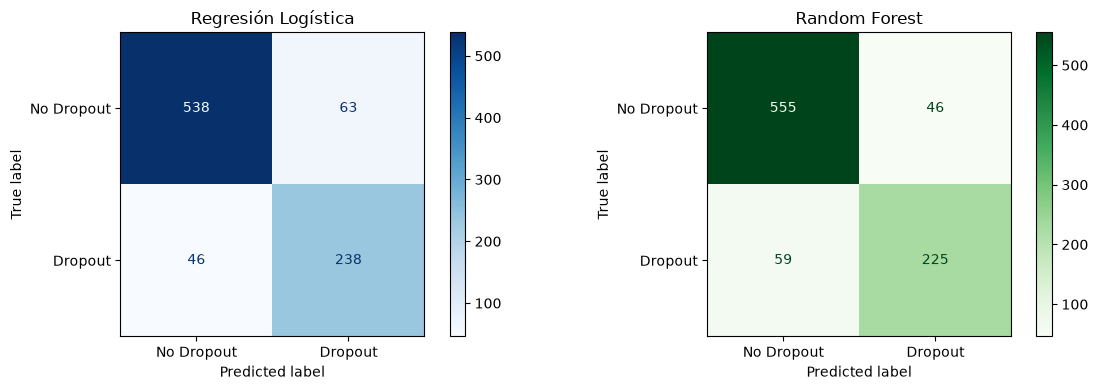

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, 
    display_labels=["No Dropout", "Dropout"], ax=axes[0], cmap="Blues")
axes[0].set_title("Regresión Logística")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf,
    display_labels=["No Dropout", "Dropout"], ax=axes[1], cmap="Greens")
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score

def metricas(y_true, y_pred, y_proba, nombre):
    return {
        "Modelo": nombre,
        "Precision (Dropout)": precision_score(y_true, y_pred),
        "Recall (Dropout)": recall_score(y_true, y_pred),
        "F1 (Dropout)": f1_score(y_true, y_pred),
        "AUC-ROC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba)
    }

resultados = pd.DataFrame([
    metricas(y_test, y_pred_lr, y_proba_lr, "Logistic Regression"),
    metricas(y_test, y_pred_rf, y_proba_rf, "Random Forest")
]).round(4)

print(resultados.to_string(index=False))

             Modelo  Precision (Dropout)  Recall (Dropout)  F1 (Dropout)  AUC-ROC  PR-AUC
Logistic Regression               0.7907            0.8380        0.8137   0.9316  0.8978
      Random Forest               0.8303            0.7923        0.8108   0.9336  0.9020


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

print("=== CV 5-fold: Logistic Regression ===")
cv_lr = cross_validate(lr_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
for m in scoring:
    print(f"{m:10s}: {cv_lr[f'test_{m}'].mean():.4f} ± {cv_lr[f'test_{m}'].std():.4f}")

print("\n=== CV 5-fold: Random Forest ===")
cv_rf = cross_validate(rf_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
for m in scoring:
    print(f"{m:10s}: {cv_rf[f'test_{m}'].mean():.4f} ± {cv_rf[f'test_{m}'].std():.4f}")

=== CV 5-fold: Logistic Regression ===
recall    : 0.8179 ± 0.0226
precision : 0.7732 ± 0.0317
f1        : 0.7944 ± 0.0193
roc_auc   : 0.9176 ± 0.0101
pr_auc    : 0.8737 ± 0.0110

=== CV 5-fold: Random Forest ===
recall    : 0.7617 ± 0.0239
precision : 0.8104 ± 0.0304
f1        : 0.7852 ± 0.0264
roc_auc   : 0.9165 ± 0.0095
pr_auc    : 0.8728 ± 0.0171


In [9]:
import joblib

MODELS_DIR = ROOT / "models"
BASELINES_DIR = MODELS_DIR / "baselines"
BASELINES_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(lr_pipeline, BASELINES_DIR / "baseline_logistic_regression.joblib")
joblib.dump(rf_pipeline, BASELINES_DIR / "baseline_random_forest.joblib")

print("Modelos base guardados en:", BASELINES_DIR)


Modelos guardados en: c:\PROYECTOS\capstone-dropout\models
['baseline_logistic_regression.joblib', 'baseline_random_forest.joblib']


In [10]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),  # maneja desbalance
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ))
])

xgb_pipeline.fit(X_train, y_train)

y_pred_xgb = xgb_pipeline.predict(X_test)
y_proba_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]

print("=== XGBOOST ===")
print(classification_report(y_test, y_pred_xgb, target_names=["No Dropout", "Dropout"]))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_xgb):.4f}")
print(f"PR-AUC (avg precision): {average_precision_score(y_test, y_proba_xgb):.4f}")

=== XGBOOST ===
              precision    recall  f1-score   support

  No Dropout       0.92      0.91      0.91       601
     Dropout       0.81      0.83      0.82       284

    accuracy                           0.88       885
   macro avg       0.86      0.87      0.87       885
weighted avg       0.88      0.88      0.88       885

AUC-ROC: 0.9336
PR-AUC (avg precision): 0.9014


             Modelo  Precision (Dropout)  Recall (Dropout)  F1 (Dropout)  AUC-ROC  PR-AUC
Logistic Regression               0.7907            0.8380        0.8137   0.9316  0.8978
      Random Forest               0.8303            0.7923        0.8108   0.9336  0.9020
            XGBoost               0.8055            0.8310        0.8180   0.9336  0.9014


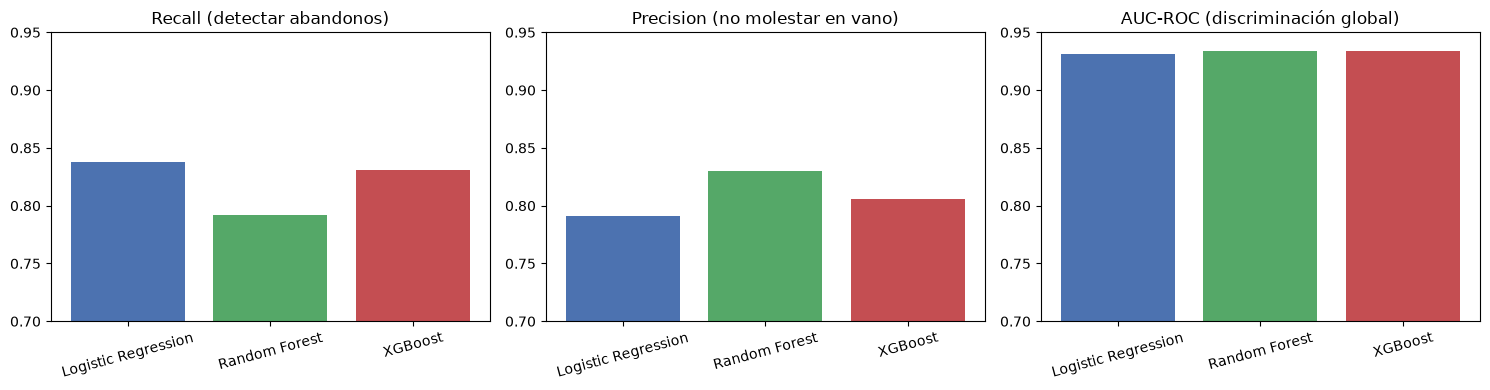

In [11]:
resultados = pd.DataFrame([
    metricas(y_test, y_pred_lr, y_proba_lr, "Logistic Regression"),
    metricas(y_test, y_pred_rf, y_proba_rf, "Random Forest"),
    metricas(y_test, y_pred_xgb, y_proba_xgb, "XGBoost")
]).round(4)

print(resultados.to_string(index=False))

# Visualización comparativa
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (metrica, titulo) in zip(axes, [
    ("Recall (Dropout)", "Recall (detectar abandonos)"),
    ("Precision (Dropout)", "Precision (no molestar en vano)"),
    ("AUC-ROC", "AUC-ROC (discriminación global)")
]):
    ax.bar(resultados["Modelo"], resultados[metrica], 
           color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_title(titulo)
    ax.set_ylim(0.7, 0.95)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [15]:
import joblib

# DECISION FINAL: XGBoost (mejor balance recall/precision/AUC)
modelo_final = xgb_pipeline
nombre_modelo = "XGBoost"

MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(modelo_final, MODELS_DIR / "modelo_final.joblib")

print(f"Modelo final guardado: {nombre_modelo}")
print(f"Archivos en models/: {[f.name for f in MODELS_DIR.iterdir()]}")
print("Siguiente paso: python scripts/build_defaults.py  (genera models/defaults.json)")


Modelo final guardado: XGBoost
Archivos en models/: ['baseline_logistic_regression.joblib', 'baseline_random_forest.joblib', 'modelo_final.joblib', 'xgboost.joblib']


Total features tras transformación: 65


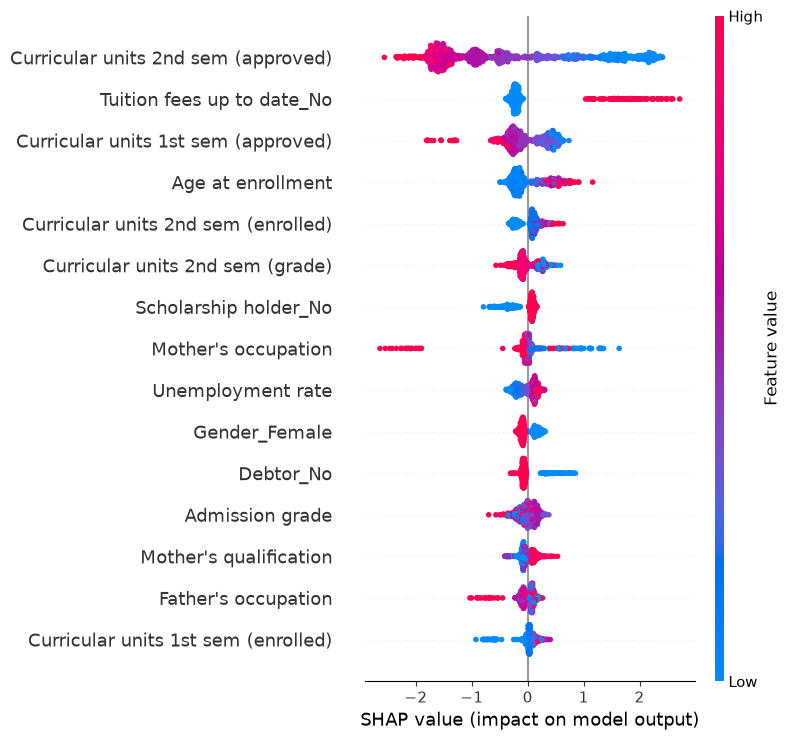

In [17]:
import shap

# Para XGBoost usamos TreeExplainer (más preciso y rápido para árboles)
xgb_model = modelo_final.named_steps["clf"]
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

feature_names = (
    num_cols + 
    list(preprocessor.named_transformers_["cat"].get_feature_names_out(cat_cols))
)
print(f"Total features tras transformación: {len(feature_names)}")

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_transformed)

# Summary plot global
plt.figure()
shap.summary_plot(shap_values, X_test_transformed, 
                  feature_names=feature_names, show=False, max_display=15)
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "06_shap_global_xgb.png", dpi=120, bbox_inches="tight")
plt.show()

Estudiante índice 2
Probabilidad de dropout: 0.873
Real: Dropout


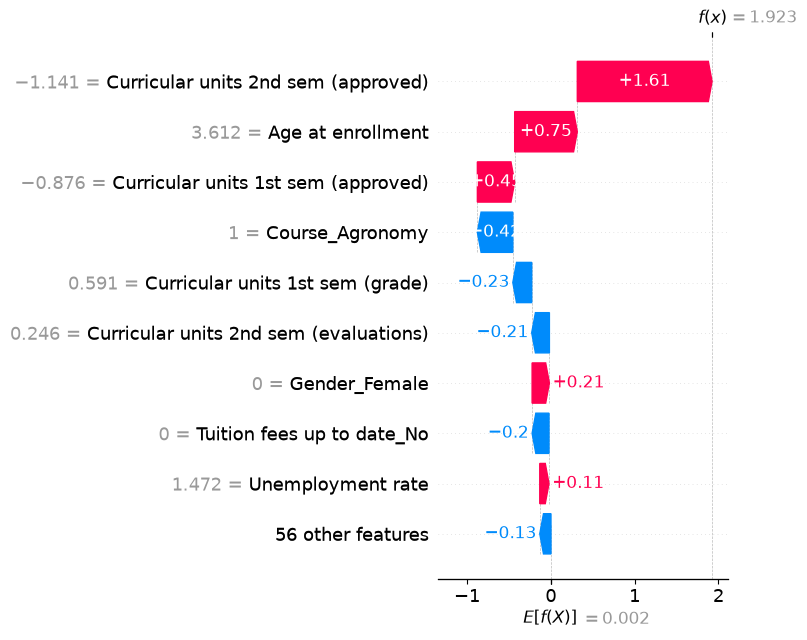

In [18]:
# Buscar un estudiante con alto riesgo
idx_alto_riesgo = np.where(y_proba_xgb > 0.7)[0][0]
print(f"Estudiante índice {idx_alto_riesgo}")
print(f"Probabilidad de dropout: {y_proba_xgb[idx_alto_riesgo]:.3f}")
print(f"Real: {'Dropout' if y_test.iloc[idx_alto_riesgo] == 1 else 'No Dropout'}")

# Waterfall plot (explicación local)
shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[idx_alto_riesgo],
        base_values=explainer.expected_value,
        data=X_test_transformed[idx_alto_riesgo],
        feature_names=feature_names
    ),
    max_display=10,
    show=False
)
plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "07_shap_local_xgb.png", dpi=120, bbox_inches="tight")
plt.show()